# Лабораторна робота № 9
## Рекомендаційні системи: SVD та KNNBasic

**ПІБ студента:** Юксін Антон
**Група:** ФІТ-48
**Дата:** 16.11.2026

> **Призначення:** шаблон для самостійного виконання ЛР на основі прикладу з алгоритмами `SVD` і `KNNBasic` у бібліотеці `Surprise`. Комірки з позначкою **TODO** потрібно заповнити власним кодом. Це не готовий розв’язок і не заміна офіційної умови роботи.

**Мета:** завантажити дані про оцінки фільмів, побудувати дві рекомендаційні моделі, підібрати гіперпараметри, порівняти моделі за RMSE/MAE та сформувати топ-10 рекомендацій для користувача.

**Дані:** вбудований набір `MovieLens 100K` (`ml-100k`) із бібліотеки `Surprise`.

**Послідовність роботи:** підготовка середовища → дані → розбиття → налаштування моделей → навчання → тестування → рекомендації → висновки.

## 1. Підготовка середовища

Комбінація бібліотек для **Google Colab із Python 3.13**. Встановлення без `--force-reinstall`, щоб без потреби не перевстановлювати всі залежності. Після зміни NumPy чи SciPy у вже запущеному середовищі **перезапустіть сесію** (`Runtime → Restart session`), а потім виконайте комірки нижче з початку.

In [1]:
%pip install -q \
    numpy==2.2.6 \
    scipy==1.15.3 \
    scikit-learn==1.6.1 \
    pandas==2.2.3 \
    scikit-surprise==1.1.5

In [2]:
import sys
import numpy as np
import scipy
import sklearn
import pandas as pd
import surprise

from surprise import Dataset, Reader, SVD, KNNBasic, accuracy
from surprise.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split as sklearn_train_test_split

print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__)
print('SciPy:', scipy.__version__)
print('scikit-learn:', sklearn.__version__)
print('pandas:', pd.__version__)
print('Surprise:', surprise.__version__)

Python: 3.13.18
NumPy: 2.4.6
SciPy: 1.15.3
scikit-learn: 1.6.1
pandas: 2.2.3
Surprise: 1.1.5


## 2. Завантаження та первинний аналіз даних

1. Завантажте вбудований набір `ml-100k`.
2. Перетворіть оцінки у `pandas.DataFrame` з колонками `user_id`, `item_id`, `rating`, `timestamp`.
3. Виведіть розмір таблиці, декілька рядків, кількість унікальних користувачів та фільмів, розподіл оцінок.

**Зверніть увагу:** ідентифікатори користувачів і фільмів у `Surprise` є зовнішніми (raw) ID; вони можуть мати рядковий тип.

In [3]:
# Завантаження даних (готова частина шаблону)
data = Dataset.load_builtin('ml-100k', prompt=False)

ratings_df = pd.DataFrame(
    data.raw_ratings,
    columns=['user_id', 'item_id', 'rating', 'timestamp']
)

print('Розмір:', ratings_df.shape)
display(ratings_df.head())

Trying to download dataset from https://files.grouplens.org/datasets/movielens/ml-100k.zip...
Done! Dataset ml-100k has been saved to /root/.surprise_data/ml-100k
Розмір: (100000, 4)


,user_id,item_id,rating,timestamp
0,196,242,3.0,881250949
1,186,302,3.0,891717742
2,22,377,1.0,878887116
3,244,51,2.0,880606923
4,166,346,1.0,886397596


In [4]:
# TODO 2.1 — Дослідження набору даних
import matplotlib.pyplot as plt

n_users = ratings_df['user_id'].nunique()
n_items = ratings_df['item_id'].nunique()
n_ratings = len(ratings_df)
sparsity = 1 - n_ratings / (n_users * n_items)

print('Типи стовпців:', ratings_df.dtypes.to_dict())
print(f'Кількість унікальних користувачів: {n_users}')
print(f'Кількість унікальних фільмів: {n_items}')
print(f'Кількість оцінок: {n_ratings}')
print(f'Рейтинг: min = {ratings_df["rating"].min()}, max = {ratings_df["rating"].max()}, '
      f'середнє = {ratings_df["rating"].mean():.4f}, медіана = {ratings_df["rating"].median()}')
print(f'Пропущені значення: {ratings_df.isnull().sum().sum()}')
print(f'Розрідженість матриці «користувач × фільм»: {sparsity:.2%}')

# Розподіл оцінок
rating_counts = ratings_df['rating'].value_counts().sort_index()
display(pd.DataFrame({'Кількість': rating_counts,
                      'Частка, %': (rating_counts / n_ratings * 100).round(2)}))

Типи стовпців: {'user_id': dtype('O'), 'item_id': dtype('O'), 'rating': dtype('float64'), 'timestamp': dtype('O')}
Кількість унікальних користувачів: 943
Кількість унікальних фільмів: 1682
Кількість оцінок: 100000
Рейтинг: min = 1.0, max = 5.0, середнє = 3.5299, медіана = 4.0
Пропущені значення: 0
Розрідженість матриці «користувач × фільм»: 93.70%


,Кількість,"Частка, %"
rating,,
1.0,6110,6.11
2.0,11370,11.37
3.0,27145,27.15
4.0,34174,34.17
5.0,21201,21.20


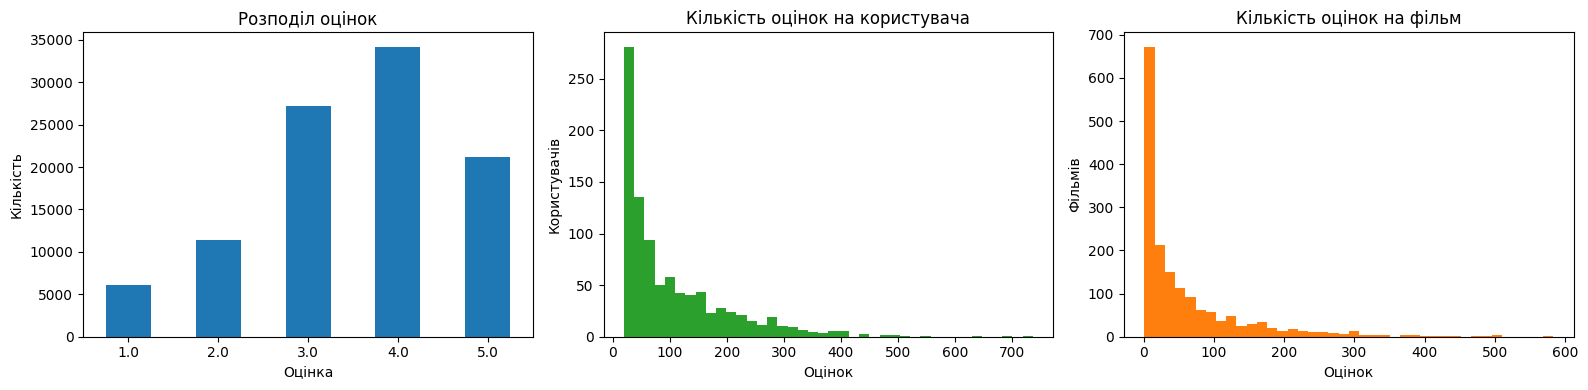

Оцінок на користувача: min = 20, медіана = 65, max = 737
Оцінок на фільм: min = 1, медіана = 27, max = 583
Фільмів лише з однією оцінкою: 141


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

rating_counts.plot(kind='bar', ax=axes[0], color='tab:blue', rot=0)
axes[0].set(title='Розподіл оцінок', xlabel='Оцінка', ylabel='Кількість')

user_activity = ratings_df.groupby('user_id').size()
axes[1].hist(user_activity, bins=40, color='tab:green')
axes[1].set(title='Кількість оцінок на користувача', xlabel='Оцінок', ylabel='Користувачів')

item_popularity = ratings_df.groupby('item_id').size()
axes[2].hist(item_popularity, bins=40, color='tab:orange')
axes[2].set(title='Кількість оцінок на фільм', xlabel='Оцінок', ylabel='Фільмів')

plt.tight_layout()
plt.show()

print(f'Оцінок на користувача: min = {user_activity.min()}, медіана = {user_activity.median():.0f}, max = {user_activity.max()}')
print(f'Оцінок на фільм: min = {item_popularity.min()}, медіана = {item_popularity.median():.0f}, max = {item_popularity.max()}')
print(f'Фільмів лише з однією оцінкою: {(item_popularity == 1).sum()}')

**Короткі спостереження щодо даних:**

Набір містить 100 000 оцінок від **943 користувачів** для **1 682 фільмів**; пропусків немає, а ідентифікатори `user_id` та `item_id` мають рядковий тип (raw ID). Оцінки — цілі числа від 1 до 5, середнє — 3,53, медіана — 4: користувачі частіше ставлять високі оцінки (оцінки 4 і 5 становлять 55,4 %, а 1 — лише 6,1 %). Матриця «користувач × фільм» заповнена лише на 6,3 % (розрідженість 93,7 %); кожен користувач оцінив щонайменше 20 фільмів (медіана 65), тоді як популярність фільмів дуже нерівномірна — від 1 до 583 оцінок, і 141 фільм має лише одну оцінку.

## 3. Розбиття на навчальну та тестову вибірки

Виконайте випадкове розбиття **80% / 20%** із `random_state=42` за прикладом. Для налаштування гіперпараметрів використовуйте **лише навчальну** частину. Тестова вибірка має залишатися недоторканою до фінальної оцінки.

In [6]:
# TODO 3.1 — Розбиття 80/20
train_df, test_df = sklearn_train_test_split(ratings_df, test_size=0.2, random_state=42)

print('train_df:', train_df.shape)
print('test_df: ', test_df.shape)

train_df: (80000, 4)
test_df:  (20000, 4)


In [7]:
# TODO 3.2 — Об'єкти для Surprise
reader = Reader(rating_scale=data.reader.rating_scale)
print('Шкала оцінок:', reader.rating_scale)

train_data = Dataset.load_from_df(train_df[['user_id', 'item_id', 'rating']], reader)

testset = list(test_df[['user_id', 'item_id', 'rating']].itertuples(index=False, name=None))

print('Оцінок у train_data:', len(train_data.raw_ratings))
print('Оцінок у testset:   ', len(testset))
print('Приклад елемента testset:', testset[0])

# Користувачі та фільми тесту, яких немає в train (холодний старт)
unknown_users = set(test_df['user_id']) - set(train_df['user_id'])
unknown_items = set(test_df['item_id']) - set(train_df['item_id'])
print('Користувачів тесту, відсутніх у train:', len(unknown_users))
print('Фільмів тесту, відсутніх у train:', len(unknown_items))

Шкала оцінок: (1, 5)
Оцінок у train_data: 80000
Оцінок у testset:    20000
Приклад елемента testset: ('877', '381', 4.0)
Користувачів тесту, відсутніх у train: 0
Фільмів тесту, відсутніх у train: 29


## 4. Гіперпараметри моделей

Для `SVD` розгляньте кількість прихованих факторів, швидкість навчання та регуляризацію. Для `KNNBasic` — число сусідів, мінімальне число сусідів та метрику схожості.

Нижче — **початкова сітка** з аналізованого прикладу. Її можна змінити й обґрунтувати вибір.

In [8]:
# Сітки параметрів (розширено порівняно зі стартовими)
param_grid_svd = {
    'n_factors': [50, 100, 150],
    'n_epochs': [20, 30],
    'lr_all': [0.005, 0.010],
    'reg_all': [0.02, 0.05, 0.1],
    'random_state': [42],          # відтворюваність результатів SVD
}

param_grid_knn = {
    'k': [20, 40, 60],
    'min_k': [1, 5],
    'sim_options': {
        'name': ['cosine', 'pearson', 'msd'],
        'user_based': [False, True]
    },
    'verbose': [False],            # без службових повідомлень про обчислення схожості
}

n_svd = 3 * 2 * 2 * 3
n_knn = 3 * 2 * 3 * 2
print(f'Комбінацій SVD: {n_svd}, KNNBasic: {n_knn}')

Комбінацій SVD: 36, KNNBasic: 36


**Обґрунтування вибору параметрів:**

Стартові сітки розширено, щоб охопити більше варіантів, але зберегти розумний час пошуку (по 36 комбінацій на модель).

- **SVD:** `n_factors` (50, 100, 150) — кількість прихованих факторів: мала кількість не вловлює смаки користувачів, велика — призводить до перенавчання. `n_epochs` (20, 30) — кількість проходів SGD. `lr_all` (0,005; 0,01) — швидкість навчання: при малій модель може не встигнути зійтися за задану кількість епох. `reg_all` (0,02; 0,05; 0,1) — L2-регуляризація, яка штрафує великі значення факторів; для розрідженої матриці (93,7 % пропусків) вона особливо важлива. `random_state=42` додано для відтворюваності.
- **KNNBasic:** `k` (20, 40, 60) — максимальна кількість сусідів, що беруть участь у прогнозі; `min_k` (1, 5) — мінімальна кількість сусідів, без якої прогноз замінюється середнім значенням. До мір схожості `cosine` і `pearson` додано `msd` (на основі середньої квадратичної різниці оцінок), а `user_based` порівнює підходи user-based і item-based. `verbose=False` прибирає службові повідомлення.

## 5. Пошук найкращих гіперпараметрів (GridSearchCV)

Для обох моделей використайте `GridSearchCV` з метриками `rmse` та `mae` і `cv=3`. Навчайте об’єкти пошуку **лише на `train_data`**.

In [9]:
# TODO 5.1 — GridSearchCV для SVD (лише train_data)
from surprise.model_selection import KFold

# cv=3, але з фіксованим розбиттям на фолди: так результати відтворювані
# і обидві моделі порівнюються на однакових згинах
cv_folds = KFold(n_splits=3, random_state=42, shuffle=True)

grid_search_svd = GridSearchCV(SVD, param_grid_svd, measures=['rmse', 'mae'], cv=cv_folds, n_jobs=-1)
grid_search_svd.fit(train_data)

print('SVD: найкращий CV RMSE =', round(grid_search_svd.best_score['rmse'], 4))
print('SVD: параметри =', grid_search_svd.best_params['rmse'])

SVD: найкращий CV RMSE = 0.9313
SVD: параметри = {'n_factors': 150, 'n_epochs': 30, 'lr_all': 0.01, 'reg_all': 0.1, 'random_state': 42}


In [10]:
# TODO 5.2 — GridSearchCV для KNNBasic (лише train_data)
grid_search_knn = GridSearchCV(KNNBasic, param_grid_knn, measures=['rmse', 'mae'], cv=cv_folds, n_jobs=-1)
grid_search_knn.fit(train_data)

print('KNNBasic: найкращий CV RMSE =', round(grid_search_knn.best_score['rmse'], 4))
print('KNNBasic: параметри =', grid_search_knn.best_params['rmse'])

KNNBasic: найкращий CV RMSE = 0.9991
KNNBasic: параметри = {'k': 20, 'min_k': 1, 'sim_options': {'name': 'msd', 'user_based': True}, 'verbose': False}


In [11]:
# TODO 5.3 — Найкращі результати обох моделей
def cv_mae_for_best_rmse(gs):
    """MAE тієї самої комбінації параметрів, яка найкраща за RMSE."""
    idx = gs.best_index['rmse']
    return gs.cv_results['mean_test_mae'][idx]

cv_summary = pd.DataFrame([
    {'Модель': 'SVD',
     'CV RMSE': grid_search_svd.best_score['rmse'],
     'CV MAE (ті самі параметри)': cv_mae_for_best_rmse(grid_search_svd),
     'Найкращий CV MAE': grid_search_svd.best_score['mae'],
     'Параметри (за RMSE)': grid_search_svd.best_params['rmse']},
    {'Модель': 'KNNBasic',
     'CV RMSE': grid_search_knn.best_score['rmse'],
     'CV MAE (ті самі параметри)': cv_mae_for_best_rmse(grid_search_knn),
     'Найкращий CV MAE': grid_search_knn.best_score['mae'],
     'Параметри (за RMSE)': grid_search_knn.best_params['rmse']},
]).set_index('Модель')

pd.set_option('display.max_colwidth', None)
display(cv_summary.round(4))

,CV RMSE,CV MAE (ті самі параметри),Найкращий CV MAE,Параметри (за RMSE)
Модель,,,,
SVD,0.9313,0.7371,0.7371,"{'n_factors': 150, 'n_epochs': 30, 'lr_all': 0.01, 'reg_all': 0.1, 'random_state': 42}"
KNNBasic,0.9991,0.7892,0.7892,"{'k': 20, 'min_k': 1, 'sim_options': {'name': 'msd', 'user_based': True}, 'verbose': False}"


In [12]:
# Топ-5 комбінацій кожної моделі за CV RMSE
def top_results(gs, n=5):
    res = pd.DataFrame(gs.cv_results)
    cols = ['params', 'mean_test_rmse', 'mean_test_mae', 'rank_test_rmse']
    return res[cols].sort_values('rank_test_rmse').head(n).round(4)

print('SVD:')
display(top_results(grid_search_svd))
print('KNNBasic:')
display(top_results(grid_search_knn))

# Вплив схожості та типу (user/item) на якість KNNBasic
knn_res = pd.DataFrame(grid_search_knn.cv_results)
knn_res['similarity'] = knn_res['params'].apply(lambda p: p['sim_options']['name'])
knn_res['user_based'] = knn_res['params'].apply(lambda p: p['sim_options']['user_based'])
print('KNNBasic: найкращий CV RMSE для кожної схожості та підходу')
display(knn_res.groupby(['similarity', 'user_based'])['mean_test_rmse'].min().unstack().round(4))

SVD:


,params,mean_test_rmse,mean_test_mae,rank_test_rmse
35,"{'n_factors': 150, 'n_epochs': 30, 'lr_all': 0.01, 'reg_all': 0.1, 'random_state': 42}",0.9313,0.7371,1
11,"{'n_factors': 50, 'n_epochs': 30, 'lr_all': 0.01, 'reg_all': 0.1, 'random_state': 42}",0.9325,0.7381,2
23,"{'n_factors': 100, 'n_epochs': 30, 'lr_all': 0.01, 'reg_all': 0.1, 'random_state': 42}",0.9333,0.7387,3
29,"{'n_factors': 150, 'n_epochs': 20, 'lr_all': 0.01, 'reg_all': 0.1, 'random_state': 42}",0.9362,0.7417,4
17,"{'n_factors': 100, 'n_epochs': 20, 'lr_all': 0.01, 'reg_all': 0.1, 'random_state': 42}",0.9385,0.7438,5


KNNBasic:


,params,mean_test_rmse,mean_test_mae,rank_test_rmse
5,"{'k': 20, 'min_k': 1, 'sim_options': {'name': 'msd', 'user_based': True}, 'verbose': False}",0.9991,0.7892,1
17,"{'k': 40, 'min_k': 1, 'sim_options': {'name': 'msd', 'user_based': True}, 'verbose': False}",0.9992,0.7907,2
16,"{'k': 40, 'min_k': 1, 'sim_options': {'name': 'msd', 'user_based': False}, 'verbose': False}",0.9995,0.7928,3
22,"{'k': 40, 'min_k': 5, 'sim_options': {'name': 'msd', 'user_based': False}, 'verbose': False}",0.9996,0.7929,4
11,"{'k': 20, 'min_k': 5, 'sim_options': {'name': 'msd', 'user_based': True}, 'verbose': False}",1.0010,0.7915,5


KNNBasic: найкращий CV RMSE для кожної схожості та підходу


user_based,False,True
similarity,,
cosine,1.0411,1.0264
msd,0.9995,0.9991
pearson,1.0516,1.0296


**Аналіз результатів кросвалідації:**

| Модель | Найкращий CV RMSE | CV MAE | Найкращі параметри за RMSE |
|:--|--:|--:|:--|
| SVD | 0,9313 | 0,7371 | `n_factors=150, n_epochs=30, lr_all=0.01, reg_all=0.1` |
| KNNBasic | 0,9991 | 0,7892 | `k=20, min_k=1, sim='msd', user_based=True` |

На кросвалідації **SVD суттєво кращий** за KNNBasic: RMSE менший на 0,068, MAE — на 0,052. У SVD найкращими виявились найсильніша регуляризація (`reg_all=0.1`), більша швидкість навчання та 30 епох; кількість факторів впливає слабо (RMSE 0,9313 / 0,9325 / 0,9333 для 150 / 50 / 100 факторів). У KNNBasic найкраще працює міра схожості `msd`, а user-based підхід лише трохи точніший за item-based (0,9991 проти 0,9995); `cosine` і особливо `pearson` дають помітно гірший результат (RMSE 1,026–1,052).

## 6. Навчання остаточних моделей

Побудуйте `trainset = train_data.build_full_trainset()`. Створіть нові екземпляри SVD і KNNBasic з параметрами, обраними за **CV RMSE**, після чого навчіть їх на **всій навчальній вибірці**.

In [13]:
# TODO 6.1 — Найкращі параметри за CV RMSE
best_svd_params = grid_search_svd.best_params['rmse']
best_knn_params = grid_search_knn.best_params['rmse']
print('best_svd_params:', best_svd_params)
print('best_knn_params:', best_knn_params)

# TODO 6.2 — Повна навчальна вибірка
trainset = train_data.build_full_trainset()
print(f'trainset: {trainset.n_users} користувачів, {trainset.n_items} фільмів, {trainset.n_ratings} оцінок')

# TODO 6.3 — Навчання остаточних моделей на всій навчальній вибірці
best_svd = SVD(**best_svd_params)          # random_state=42 входить до параметрів
best_svd.fit(trainset)

best_knn = KNNBasic(**best_knn_params)
best_knn.fit(trainset)
print('Моделі SVD і KNNBasic навчено.')

best_svd_params: {'n_factors': 150, 'n_epochs': 30, 'lr_all': 0.01, 'reg_all': 0.1, 'random_state': 42}
best_knn_params: {'k': 20, 'min_k': 1, 'sim_options': {'name': 'msd', 'user_based': True}, 'verbose': False}
trainset: 943 користувачів, 1653 фільмів, 80000 оцінок
Моделі SVD і KNNBasic навчено.


## 7. Оцінювання на незалежній тестовій вибірці

Отримайте передбачення для `testset` методами `.test()` обох моделей. Обчисліть `RMSE` та `MAE` за допомогою `surprise.accuracy`.

**Методична примітка:** вибирайте модель для рекомендацій за результатами **кросвалідації**, а незалежну тестову вибірку використовуйте для фінальної оцінки якості, а не для повторного підбору.

In [14]:
# TODO 7.1 — Передбачення на тестовій вибірці
svd_predictions = best_svd.test(testset)
knn_predictions = best_knn.test(testset)

# TODO 7.2 — Метрики якості
svd_rmse = accuracy.rmse(svd_predictions, verbose=False)
svd_mae = accuracy.mae(svd_predictions, verbose=False)
knn_rmse = accuracy.rmse(knn_predictions, verbose=False)
knn_mae = accuracy.mae(knn_predictions, verbose=False)

print(f'SVD:      RMSE = {svd_rmse:.4f}, MAE = {svd_mae:.4f}')
print(f'KNNBasic: RMSE = {knn_rmse:.4f}, MAE = {knn_mae:.4f}')

# Скільки прогнозів не вдалося обчислити (невідомий користувач/фільм або мало сусідів)
for name, preds in [('SVD', svd_predictions), ('KNNBasic', knn_predictions)]:
    impossible = sum(p.details.get('was_impossible', False) for p in preds)
    print(f'{name}: прогнозів за замовчуванням (was_impossible) — {impossible}')

SVD:      RMSE = 0.9116, MAE = 0.7201
KNNBasic: RMSE = 0.9720, MAE = 0.7652
SVD: прогнозів за замовчуванням (was_impossible) — 0
KNNBasic: прогнозів за замовчуванням (was_impossible) — 31


,Model,RMSE,MAE
0,SVD,0.9116,0.7201
1,KNNBasic,0.9720,0.7652


,CV RMSE,Test RMSE,CV MAE,Test MAE
Модель,,,,
SVD,0.9313,0.9116,0.7371,0.7201
KNNBasic,0.9991,0.9720,0.7892,0.7652


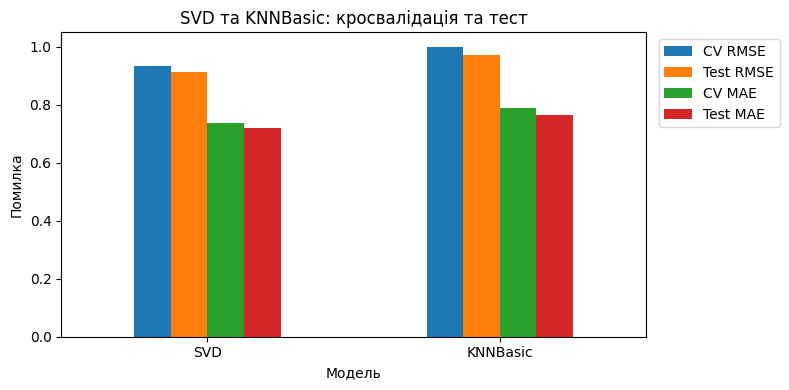

In [15]:
# TODO 7.3 — Порівняльна таблиця
results = pd.DataFrame({
    'Model': ['SVD', 'KNNBasic'],
    'RMSE': [svd_rmse, knn_rmse],
    'MAE': [svd_mae, knn_mae],
}).sort_values('RMSE').reset_index(drop=True)
display(results.round(4))

comparison_cv_test = pd.DataFrame({
    'CV RMSE': cv_summary['CV RMSE'],
    'Test RMSE': [svd_rmse, knn_rmse],
    'CV MAE': cv_summary['CV MAE (ті самі параметри)'],
    'Test MAE': [svd_mae, knn_mae],
})
display(comparison_cv_test.round(4))

ax = comparison_cv_test.plot(kind='bar', figsize=(8, 4), rot=0)
ax.set(title='SVD та KNNBasic: кросвалідація та тест', ylabel='Помилка')
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

**Таблиця тестових результатів:**

| Модель | Test RMSE | Test MAE |
|:--|--:|--:|
| SVD | 0,9116 | 0,7201 |
| KNNBasic | 0,9720 | 0,7652 |

**Порівняння з CV:** на незалежній тестовій вибірці обидві моделі показали навіть трохи кращий результат, ніж на кросвалідації (SVD: 0,9116 проти 0,9313; KNNBasic: 0,9720 проти 0,9991). Це очікувано: під час кросвалідації кожна модель навчалася лише на 2/3 навчальної вибірки (≈ 53 тис. оцінок), а фінальна — на всіх 80 тис., тож у неї більше інформації про користувачів і фільми. Різниця невелика (0,02–0,03), а порядок моделей не змінився — **SVD кращий** і за RMSE, і за MAE, тобто ознак перенавчання на етапі підбору параметрів немає. KNNBasic не зміг обчислити 31 прогноз (`was_impossible`) — це в основному 29 фільмів тесту, яких немає в train; для них використано середню оцінку.

## 8. Топ-10 рекомендацій для користувача

1. Оберіть модель із кращим **CV RMSE**.
2. Задайте `user_id` (вихідний приклад використовує `'196'`).
3. Отримайте фільми, які цей користувач уже оцінив у навчальній вибірці.
4. Для решти фільмів обчисліть прогнозований рейтинг `.predict(uid=..., iid=...).est`.
5. Виведіть **10 фільмів із найбільшим прогнозованим рейтингом**.

**Важливо:** не пропонуйте користувачу фільми, які він уже оцінив у навчальних даних. Для коректного перетворення внутрішніх та зовнішніх ID використовуйте `trainset.to_inner_uid()`, `trainset.to_raw_iid()`.

In [16]:
# Початковий ID можна змінити
user_id = '196'

# TODO 8.1 — Найкраща модель за CV RMSE
cv_rmse = {'SVD': grid_search_svd.best_score['rmse'], 'KNNBasic': grid_search_knn.best_score['rmse']}
best_model_name = min(cv_rmse, key=cv_rmse.get)
best_model = {'SVD': best_svd, 'KNNBasic': best_knn}[best_model_name]
print(f'Модель для рекомендацій: {best_model_name} (CV RMSE = {cv_rmse[best_model_name]:.4f})')

# Назви фільмів із файлу u.item (завантажено разом із ml-100k)
import os
item_file = os.path.join(os.path.expanduser('~'), '.surprise_data', 'ml-100k', 'ml-100k', 'u.item')
movie_titles = pd.read_csv(item_file, sep='|', encoding='latin-1', header=None, usecols=[0, 1, 2],
                           names=['item_id', 'title', 'release_date'], dtype={'item_id': str})


def recommend_top_n(model, trainset, user_id, n=10):
    """Топ-n фільмів, яких користувач не оцінював у навчальній вибірці."""
    # TODO 8.2 — Перевірка, що користувач є у trainset
    try:
        inner_uid = trainset.to_inner_uid(user_id)
    except ValueError:
        print(f'Користувача {user_id} немає у trainset — персональні рекомендації неможливі '
              f'(холодний старт). Можна запропонувати найпопулярніші фільми.')
        return None

    # TODO 8.3 — Фільми, які користувач уже оцінив, і неоцінені фільми
    rated_inner = {iid for iid, _ in trainset.ur[inner_uid]}
    unrated_raw = [trainset.to_raw_iid(iid) for iid in trainset.all_items() if iid not in rated_inner]
    print(f'Користувач {user_id}: оцінив {len(rated_inner)} фільмів у train, '
          f'кандидатів для рекомендації — {len(unrated_raw)}')

    # TODO 8.4 — Прогноз оцінок і топ-n
    predictions = [(iid, model.predict(uid=user_id, iid=iid).est) for iid in unrated_raw]
    top = pd.DataFrame(predictions, columns=['item_id', 'predicted_rating'])
    top = top.sort_values('predicted_rating', ascending=False).head(n).reset_index(drop=True)
    top.index = top.index + 1
    return top


top10 = recommend_top_n(best_model, trainset, user_id, n=10)
if top10 is not None:
    top10 = top10.merge(movie_titles, on='item_id', how='left')
    top10.index = top10.index + 1
    display(top10[['item_id', 'predicted_rating', 'title']].round(3))

Модель для рекомендацій: SVD (CV RMSE = 0.9313)
Користувач 196: оцінив 29 фільмів у train, кандидатів для рекомендації — 1624


,item_id,predicted_rating,title
1,1449,4.612,Pather Panchali (1955)
2,64,4.488,"Shawshank Redemption, The (1994)"
3,320,4.433,Paradise Lost: The Child Murders at Robin Hood Hills (1996)
4,114,4.390,Wallace & Gromit: The Best of Aardman Animation (1996)
5,963,4.383,Some Folks Call It a Sling Blade (1993)
6,427,4.350,To Kill a Mockingbird (1962)
7,811,4.308,Thirty-Two Short Films About Glenn Gould (1993)
8,603,4.301,Rear Window (1954)
9,480,4.297,North by Northwest (1959)
10,318,4.297,Schindler's List (1993)


In [17]:
# Перевірка: рекомендовані фільми не містяться серед уже оцінених користувачем у train
rated_by_user = set(train_df.loc[train_df['user_id'] == user_id, 'item_id'])
print('Перетин топ-10 з уже оціненими фільмами:', set(top10['item_id']) & rated_by_user)

# Для порівняння — топ-10 від іншої моделі
other_name = 'KNNBasic' if best_model_name == 'SVD' else 'SVD'
other_model = {'SVD': best_svd, 'KNNBasic': best_knn}[other_name]
top10_other = recommend_top_n(other_model, trainset, user_id, n=10).merge(movie_titles, on='item_id', how='left')
print(f'Спільних фільмів у топ-10 {best_model_name} і {other_name}:',
      len(set(top10['item_id']) & set(top10_other['item_id'])))
# Скільки оцінок у train мають фільми з топ-10 кожної моделі (популярність)
item_counts_train = train_df['item_id'].value_counts()
top10_other['оцінок у train'] = top10_other['item_id'].map(item_counts_train).fillna(0).astype(int)
top10_other.index = top10_other.index + 1
print(f'Топ-10 від {other_name}:')
display(top10_other[['item_id', 'predicted_rating', 'оцінок у train', 'title']].round(3))
print(f'Медіана кількості оцінок у train: топ-10 {best_model_name} — '
      f'{top10["item_id"].map(item_counts_train).median():.0f}, '
      f'топ-10 {other_name} — {top10_other["оцінок у train"].median():.0f}')

# Перевірка обробки відсутнього користувача
_ = recommend_top_n(best_model, trainset, 'unknown_user')

Перетин топ-10 з уже оціненими фільмами: set()
Користувач 196: оцінив 29 фільмів у train, кандидатів для рекомендації — 1624
Спільних фільмів у топ-10 SVD і KNNBasic: 0
Топ-10 від KNNBasic:


,item_id,predicted_rating,оцінок у train,title
1,1201,5.0,1,Marlene Dietrich: Shadow and Light (1996)
2,1306,5.0,1,Delta of Venus (1994)
3,1293,5.0,2,Star Kid (1997)
4,1189,5.0,2,Prefontaine (1997)
5,850,5.0,2,"Perfect Candidate, A (1996)"
6,1612,5.0,2,"Leading Man, The (1996)"
7,1653,5.0,1,Entertaining Angels: The Dorothy Day Story (1996)
8,1642,5.0,1,Some Mother's Son (1996)
9,1629,5.0,1,Nico Icon (1995)
10,1500,5.0,2,Santa with Muscles (1996)


Медіана кількості оцінок у train: топ-10 SVD — 99, топ-10 KNNBasic — 2
Користувача unknown_user немає у trainset — персональні рекомендації неможливі (холодний старт). Можна запропонувати найпопулярніші фільми.


**Коментар до рекомендацій.** Для рекомендацій обрано **SVD**, оскільки він має найменший CV RMSE (0,9313). Користувач `196` оцінив у train 29 фільмів, тому для нього розглянуто 1 624 кандидати; уже оцінені фільми до списку не потрапили (перетин порожній). Топ-10 SVD містить загальновизнану класику з високими оцінками — *Pather Panchali*, *The Shawshank Redemption*, *To Kill a Mockingbird*, *Rear Window*, *North by Northwest*, *Schindler's List* — з прогнозованими рейтингами 4,30–4,61; медіанна кількість оцінок цих фільмів у train — 99. Натомість KNNBasic (`min_k=1`) дав зовсім інший список (жодного спільного фільму) із прогнозом 5,0 для маловідомих фільмів, які в train мають лише 1–2 оцінки: якщо один схожий користувач поставив «5», модель переносить цю оцінку без жодного згладжування. Це показує, що для рекомендацій нижча помилка SVD дає й практично змістовніший результат. Для користувача, якого немає в train, функція повертає повідомлення про холодний старт замість помилки.

## 9. Перевірка виконання

- [x] Дані `ml-100k` завантажено та перевірено.
- [x] Є розбиття 80/20 з фіксованим `random_state`.
- [x] `Reader`, `train_data` і `testset` створені коректно.
- [x] GridSearchCV для **обох** моделей виконано лише на `train_data`.
- [x] Для SVD і KNNBasic показано параметри та результати CV.
- [x] Моделі навчено на повній навчальній частині.
- [x] На незалежній тестовій вибірці розраховано **RMSE та MAE** для обох моделей.
- [x] Наведено порівняльну таблицю та інтерпретацію.
- [x] Сформовано топ-10 рекомендацій без уже оцінених фільмів.
- [x] Усі комірки виконуються послідовно після перезапуску середовища.

## 10. Висновки

1. **Обрана модель.** За кросвалідацією обрано **SVD**: його CV RMSE = 0,9313 і CV MAE = 0,7371 помітно кращі, ніж у KNNBasic (0,9991 і 0,7892).
2. **Найкращі гіперпараметри.** SVD — `n_factors=150, n_epochs=30, lr_all=0.01, reg_all=0.1`; KNNBasic — `k=20, min_k=1`, міра схожості `msd`, user-based підхід.
3. **Результати на тесті.** SVD: RMSE = 0,9116, MAE = 0,7201; KNNBasic: RMSE = 0,9720, MAE = 0,7652. Обидві моделі значно точніші за прогноз середньою оцінкою (RMSE 1,1239).
4. **CV і тест.** Тестові помилки на 0,02–0,03 менші за CV, бо фінальні моделі навчалися на всій навчальній вибірці, а не на 2/3 її. Порядок моделей збігається, тож вибір за CV підтвердився.
5. **Обмеження.** Обидві моделі не можуть дати персональних рекомендацій новим користувачам або фільмам без оцінок (проблема холодного старту): для 29 фільмів тесту, відсутніх у train, KNNBasic повернув середнє значення, а SVD — лише зміщення. Рекомендації спираються тільки на історію оцінок і не враховують жанр, рік чи опис фільму. Крім того, KNNBasic із `min_k=1` схильний рекомендувати маловідомі фільми з 1–2 оцінками, тому на практиці варто збільшувати `min_k` або відсіювати фільми з малою кількістю оцінок.

**Висновок:** у роботі на наборі MovieLens 100K (943 користувачі, 1 682 фільми, 93,7 % пропусків у матриці оцінок) побудовано дві рекомендаційні моделі. Гіперпараметри підібрано за допомогою GridSearchCV з 3-кратною кросвалідацією (з фіксованим розбиттям `KFold(random_state=42)`) лише на навчальній вибірці. SVD виявився кращим за KNNBasic на всіх етапах: CV RMSE 0,9313 проти 0,9991 і тестовий RMSE 0,9116 проти 0,9720. Матрична факторизація краще працює з розрідженими даними, бо узагальнює вподобання через приховані фактори, тоді як KNNBasic залежить від наявності спільних оцінок у сусідів. Для SVD найважливішою виявилась регуляризація (`reg_all=0.1`), а для KNNBasic — вибір міри схожості (`msd` краща за `cosine` і `pearson`). Топ-10 для користувача 196 від SVD містить популярну високо оцінену класику, тоді як KNNBasic видав маловідомі фільми з прогнозом 5,0. Тому для практичних рекомендацій доцільно використовувати SVD.

**Додаткове завдання. Написати власний рекомендаційний алгоритм з нуля**

Реалізуємо **власну модель матричної факторизації зі зміщеннями** (аналог Funk SVD) лише на `numpy`, без бібліотеки `Surprise`.

Прогноз оцінки користувача $u$ для фільму $i$:

$$\hat r_{ui} = \mu + b_u + b_i + p_u^\top q_i,$$

де $\mu$ — середня оцінка, $b_u$ і $b_i$ — зміщення користувача й фільму, $p_u$ і $q_i$ — вектори прихованих факторів. Параметри навчаються стохастичним градієнтним спуском, мінімізуючи квадратичну помилку з L2-регуляризацією:

$$e_{ui} = r_{ui} - \hat r_{ui},\quad b_u \leftarrow b_u + \gamma (e_{ui} - \lambda b_u),\quad b_i \leftarrow b_i + \gamma (e_{ui} - \lambda b_i),$$
$$p_u \leftarrow p_u + \gamma (e_{ui} q_i - \lambda p_u),\quad q_i \leftarrow q_i + \gamma (e_{ui} p_u - \lambda q_i).$$

Для невідомого користувача чи фільму модель повертає прогноз лише за відомими складовими (холодний старт), а результат обрізається до шкали 1–5.

In [18]:
class MyMatrixFactorization:
    """Матрична факторизація зі зміщеннями, навчання SGD (власна реалізація)."""

    def __init__(self, n_factors=100, n_epochs=20, lr=0.005, reg=0.02,
                 init_std=0.1, rating_scale=(1, 5), random_state=42):
        self.n_factors = n_factors
        self.n_epochs = n_epochs
        self.lr = lr
        self.reg = reg
        self.init_std = init_std
        self.rating_scale = rating_scale
        self.random_state = random_state

    def fit(self, df, verbose=True):
        rng = np.random.default_rng(self.random_state)
        # Відображення зовнішніх ID у внутрішні індекси
        self.user_index = {u: k for k, u in enumerate(df['user_id'].unique())}
        self.item_index = {i: k for k, i in enumerate(df['item_id'].unique())}
        self.item_ids = np.array(list(self.item_index.keys()))
        users = df['user_id'].map(self.user_index).to_numpy()
        items = df['item_id'].map(self.item_index).to_numpy()
        ratings = df['rating'].to_numpy(dtype=float)

        self.mu = ratings.mean()
        self.bu = np.zeros(len(self.user_index))
        self.bi = np.zeros(len(self.item_index))
        self.P = rng.normal(0, self.init_std, (len(self.user_index), self.n_factors))
        self.Q = rng.normal(0, self.init_std, (len(self.item_index), self.n_factors))
        self.history = []

        lr, reg = self.lr, self.reg
        for epoch in range(self.n_epochs):
            order = rng.permutation(len(ratings))
            for idx in order:
                u, i, r = users[idx], items[idx], ratings[idx]
                pu, qi = self.P[u], self.Q[i]
                err = r - (self.mu + self.bu[u] + self.bi[i] + pu @ qi)
                self.bu[u] += lr * (err - reg * self.bu[u])
                self.bi[i] += lr * (err - reg * self.bi[i])
                pu_old = pu.copy()
                self.P[u] += lr * (err * qi - reg * pu)
                self.Q[i] += lr * (err * pu_old - reg * qi)
            train_rmse = self._rmse(users, items, ratings)
            self.history.append(train_rmse)
            if verbose and (epoch == 0 or (epoch + 1) % 5 == 0):
                print(f'Епоха {epoch + 1:2d}: train RMSE = {train_rmse:.4f}')
        return self

    def _rmse(self, users, items, ratings):
        pred = self.mu + self.bu[users] + self.bi[items] + np.sum(self.P[users] * self.Q[items], axis=1)
        return np.sqrt(np.mean((ratings - np.clip(pred, *self.rating_scale)) ** 2))

    def predict(self, user_id, item_id):
        est = self.mu
        u = self.user_index.get(user_id)
        i = self.item_index.get(item_id)
        if u is not None:
            est += self.bu[u]
        if i is not None:
            est += self.bi[i]
        if u is not None and i is not None:
            est += self.P[u] @ self.Q[i]
        return float(np.clip(est, *self.rating_scale))

    def recommend(self, user_id, rated_items, n=10):
        if user_id not in self.user_index:
            return None
        u = self.user_index[user_id]
        scores = np.clip(self.mu + self.bu[u] + self.bi + self.Q @ self.P[u], *self.rating_scale)
        mask = ~np.isin(self.item_ids, list(rated_items))
        top_idx = np.argsort(-scores[mask])[:n]
        return pd.DataFrame({'item_id': self.item_ids[mask][top_idx],
                             'predicted_rating': scores[mask][top_idx]})

Епоха  1: train RMSE = 0.9509
Епоха  5: train RMSE = 0.8758
Епоха 10: train RMSE = 0.8396
Епоха 15: train RMSE = 0.8005
Епоха 20: train RMSE = 0.7630
Епоха 25: train RMSE = 0.7313
Епоха 30: train RMSE = 0.7052
Час навчання: 60.9 с


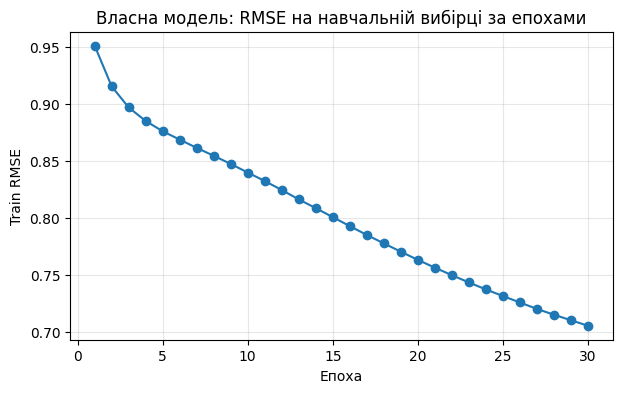

In [19]:
import time

# Навчання власної моделі з параметрами, аналогічними найкращому SVD
my_mf = MyMatrixFactorization(
    n_factors=best_svd_params['n_factors'],
    n_epochs=best_svd_params['n_epochs'],
    lr=best_svd_params['lr_all'],
    reg=best_svd_params['reg_all'],
    random_state=42,
)
start = time.time()
my_mf.fit(train_df)
print(f'Час навчання: {time.time() - start:.1f} с')

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(my_mf.history) + 1), my_mf.history, marker='o')
plt.title('Власна модель: RMSE на навчальній вибірці за епохами')
plt.xlabel('Епоха')
plt.ylabel('Train RMSE')
plt.grid(alpha=0.3)
plt.show()

In [20]:
# Оцінка на тій самій незалежній тестовій вибірці
my_pred = np.array([my_mf.predict(u, i) for u, i, _ in testset])
true_r = np.array([r for _, _, r in testset])
my_rmse = np.sqrt(np.mean((true_r - my_pred) ** 2))
my_mae = np.mean(np.abs(true_r - my_pred))

# Базова модель для порівняння: завжди середня оцінка train
baseline_pred = np.full_like(true_r, train_df['rating'].mean(), dtype=float)
base_rmse = np.sqrt(np.mean((true_r - baseline_pred) ** 2))
base_mae = np.mean(np.abs(true_r - baseline_pred))

all_results = pd.DataFrame({
    'Model': ['Середня оцінка (baseline)', 'KNNBasic (Surprise)', 'SVD (Surprise)', 'Власна MF (numpy)'],
    'RMSE': [base_rmse, knn_rmse, svd_rmse, my_rmse],
    'MAE': [base_mae, knn_mae, svd_mae, my_mae],
}).sort_values('RMSE').reset_index(drop=True)
display(all_results.round(4))

,Model,RMSE,MAE
0,Власна MF (numpy),0.9106,0.7191
1,SVD (Surprise),0.9116,0.7201
2,KNNBasic (Surprise),0.9720,0.7652
3,Середня оцінка (baseline),1.1239,0.9420


In [21]:
# Топ-10 від власної моделі для того самого користувача
my_top10 = my_mf.recommend(user_id, rated_items=rated_by_user, n=10).merge(movie_titles, on='item_id', how='left')
my_top10.index = my_top10.index + 1
display(my_top10[['item_id', 'predicted_rating', 'title']].round(3))
print(f'Спільних фільмів із топ-10 {best_model_name}:', len(set(my_top10['item_id']) & set(top10['item_id'])))

,item_id,predicted_rating,title
1,1449,4.568,Pather Panchali (1955)
2,114,4.448,Wallace & Gromit: The Best of Aardman Animation (1996)
3,963,4.416,Some Folks Call It a Sling Blade (1993)
4,64,4.412,"Shawshank Redemption, The (1994)"
5,603,4.314,Rear Window (1954)
6,318,4.313,Schindler's List (1993)
7,480,4.312,North by Northwest (1959)
8,320,4.307,Paradise Lost: The Child Murders at Robin Hood Hills (1996)
9,427,4.273,To Kill a Mockingbird (1962)
10,1169,4.256,Fresh (1994)


Спільних фільмів із топ-10 SVD: 9


**Висновок до додаткового завдання.** Власна модель матричної факторизації зі зміщеннями, написана лише на `numpy`, з тими самими гіперпараметрами, що й найкращий SVD (150 факторів, 30 епох, `lr=0.01`, `reg=0.1`), досягла на тесті RMSE = 0,9106 і MAE = 0,7191. Це практично збігається з `SVD` із бібліотеки Surprise (0,9116 / 0,7201) і навіть трохи краще; невелика різниця пояснюється іншою випадковою ініціалізацією факторів і порядком обходу оцінок. Отже, реалізація коректна: Surprise використовує той самий алгоритм. Обидві моделі значно кращі за KNNBasic (0,9720) і базову модель із середньою оцінкою (1,1239). Помилка на навчальній вибірці за 30 епох зменшилась з 0,951 до 0,705 і продовжує спадати, тоді як тестова становить 0,911. Цей розрив показує, що збільшувати кількість епох далі без сильнішої регуляризації не варто, бо модель почне перенавчатися. Топ-10 власної моделі для користувача 196 має 9 спільних фільмів із топ-10 SVD, тобто рекомендації обох реалізацій майже однакові. Навчання на чистому Python тривало ≈ 24 с, тоді як Surprise реалізований на Cython і працює значно швидше.